# Three-Dimensional Detector-Graph Decoding under Uniform and Nonuniform Fault Models

A numerical investigation of graphlike detector syndromes, open-boundary minimum-weight perfect matching (MWPM), logical parity, and phenomenological noise models on small three-dimensional cubic lattices.

The notebook is organized into **eight sections covering the base model**, followed by **Part 9: likelihood-weighted decoding under nonuniform edge-fault probabilities**. Analytical consistency checks, Monte Carlo estimates, and visualizations are included alongside the implementation.

**Scope.** The cubic lattice is a deliberately simplified *detector graph*, not a circuit-derived Raussendorf–Harrington–Goyal (RHG) photonic cluster state. The parameter `distance` labels a lattice size; it is not an established RHG code distance. The optional Stim/PyMatching example uses a repeated rotated surface-code memory and is a separate reference benchmark.

In [1]:
import importlib.util
from dataclasses import dataclass
from IPython.display import display
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

print("NumPy:", np.__version__, "| NetworkX:", nx.__version__)

NumPy: 2.3.5 | NetworkX: 3.6.1


### Reference implementation
The detector graph, binary syndrome map, matching correction, stochastic sampling, and resource-availability calculations are defined below. Keeping the implementation in the notebook makes the analysis reproducible without a separate Python module.

In [2]:
@dataclass(frozen=True)
class DetectorGraph:
    distance: int
    graph: nx.Graph
    edges: tuple
    detectors: tuple
    boundary_left: tuple
    boundary_right: tuple
    incidence: np.ndarray
    logical: np.ndarray


def make_detector_graph(distance: int) -> DetectorGraph:
    """Cubic 3D matching graph; x-end surfaces are absorbing boundaries.

    Detectors lie at 1 <= x <= d-2. All candidate fault edges must touch
    at least one detector. A cut between x=0 and x=1 defines a logical bit.
    The shortest boundary-to-boundary fault chain has d_eff=d-1 edges.
    Hence d=4 or 6 gives odd geometric lengths 3 or 5, respectively.
    This geometric length is not a validated physical RHG code distance.
    """
    if not isinstance(distance, int) or distance < 3:
        raise ValueError('distance must be an integer >=3')
    d=distance
    g=nx.grid_graph(dim=[range(d),range(d),range(d)])
    # Graph nodes are 3-tuples; the first coordinate is interpreted as x.
    # Remove boundary-plane tangential edges (their errors are invisible).
    g.remove_edges_from([(u,v) for u,v in list(g.edges())
                         if u[0]==v[0] and u[0] in (0,d-1)])
    edges=tuple(sorted(tuple(sorted((u,v))) for u,v in g.edges()))
    detector_nodes=tuple(sorted(n for n in g.nodes() if 0<n[0]<d-1))
    left=tuple(sorted(n for n in g.nodes() if n[0]==0))
    right=tuple(sorted(n for n in g.nodes() if n[0]==d-1))
    row={node:i for i,node in enumerate(detector_nodes)}
    H=np.zeros((len(row),len(edges)),dtype=np.uint8)
    logical=np.zeros(len(edges),dtype=np.uint8)
    for j,(u,v) in enumerate(edges):
        for n in (u,v):
            if n in row:
                H[row[n],j]=1
        logical[j]=int(min(u[0],v[0])==0 and max(u[0],v[0])==1)
    assert np.all(H.sum(axis=0)<=2)
    return DetectorGraph(d,g,edges,detector_nodes,left,right,H,logical)


def sample_errors(model: DetectorGraph, probability: float, shots: int, seed=0):
    if not 0<=probability<=1:
        raise ValueError('probability must be in [0,1]')
    if not isinstance(shots,int) or shots<1:
        raise ValueError('shots must be positive integer')
    rng=np.random.default_rng(seed)
    errors=(rng.random((shots,len(model.edges)))<probability).astype(np.uint8)
    syndrome=((errors.astype(np.int32) @ model.incidence.T.astype(np.int32))%2).astype(np.uint8)
    obs=((errors.astype(np.int32) @ model.logical.astype(np.int32))%2).astype(np.uint8)
    return errors,syndrome,obs


def shortest_correction(model: DetectorGraph, syndrome: np.ndarray):
    """MWPM over detection events with optional left/right boundary pairing.

    Uses unit edge weights; correct for uniform independent edge error rates
    p<0.5 up to shortest-path degeneracy and matching tie breaks. The graph
    is small by design and is NOT a scalable production decoder.
    """
    syn=np.asarray(syndrome,dtype=np.uint8).reshape(-1)
    if syn.size!=len(model.detectors):
        raise ValueError('syndrome length mismatch')
    defects=[model.detectors[i] for i in np.flatnonzero(syn)]
    correction=np.zeros(len(model.edges),dtype=np.uint8)
    if not defects:
        return correction
    g=model.graph
    n=len(defects)
    edge_map={e:i for i,e in enumerate(model.edges)}
    boundary=set(model.boundary_left)|set(model.boundary_right)
    # Multi-source BFS from both boundary surfaces. Paths are reconstructed.
    def nearest_boundary_path(v):
        # nearest boundary by a BFS starting at v
        from collections import deque
        q=deque([v]); previous={v:None}
        goal=None
        while q:
            x=q.popleft()
            if x in boundary:
                goal=x;break
            for y in g.neighbors(x):
                if y not in previous:
                    previous[y]=x;q.append(y)
        path=[]
        while goal is not None:
            path.append(goal);goal=previous[goal]
        return path[::-1]
    bpaths=[nearest_boundary_path(d) for d in defects]
    m=nx.Graph()
    # 'real' 0...n-1, 'virtual' n...2n-1.
    m.add_nodes_from(range(2*n))
    for i in range(n):
        for j in range(i+1,n):
            m.add_edge(i,j,weight=len(nx.shortest_path(g,defects[i],defects[j]))-1)
    for i in range(n):
        m.add_edge(i,n+i,weight=len(bpaths[i])-1)
    for i in range(n):
        for j in range(i+1,n):
            m.add_edge(n+i,n+j,weight=0)
    pairing=nx.algorithms.matching.min_weight_matching(m,weight='weight')
    for a,b in pairing:
        if a>=n and b>=n:
            continue
        if a>=n:
            a,b=b,a
        if b>=n:
            path=bpaths[a]
        else:
            path=nx.shortest_path(g,defects[a],defects[b])
        for u,v in zip(path[:-1],path[1:]):
            correction[edge_map[tuple(sorted((u,v)))]]^=1
    # Verifies inferred correction explains observed detector events.
    assert np.array_equal((model.incidence.astype(np.int32)@correction.astype(np.int32))%2,syn)
    return correction


def decode_shots(model, syndromes):
    return np.array([int(np.dot(model.logical.astype(np.int32),
                              shortest_correction(model,s).astype(np.int32))%2)
                     for s in syndromes],dtype=np.uint8)


def logical_error_rate(distance=3,p=0.02,shots=200,seed=0):
    model=make_detector_graph(distance)
    _,syndrome,actual=sample_errors(model,p,shots,seed)
    predicted=decode_shots(model,syndrome)
    failures=int(np.count_nonzero(predicted!=actual))
    rate=failures/shots
    se=float(np.sqrt(rate*(1-rate)/shots))
    return {'distance':distance,'p':p,'shots':shots,'failures':failures,
            'logical_error_rate':rate,'standard_error':se}


def erasure_no_error_probability(n_components,loss):
    if n_components<0 or not 0<=loss<=1:
        raise ValueError('invalid count or loss')
    return (1-loss)**n_components


def link_budget(n_photons,source_efficiency,channel_efficiency,detector_efficiency):
    for x in (source_efficiency,channel_efficiency,detector_efficiency):
        if not 0<=x<=1:
            raise ValueError('efficiencies must be in [0,1]')
    if n_photons<0:
        raise ValueError('n_photons must be >= 0')
    per_photon=source_efficiency*channel_efficiency*detector_efficiency
    return {'per_photon_survival':per_photon,
            'all_present_probability':per_photon**n_photons}


## Part 1 — Architecture and RHG context
Photonic cluster-state computation starts from a graph state
$$|G\rangle=\prod_{(i,j)\in E}CZ_{ij}|+\rangle^{\otimes n},\qquad K_v=X_v\prod_{u\in N(v)}Z_u.$$
A genuine RHG construction requires a specified **three-dimensional primal/dual cell complex, stabilizers, measurement bases, temporal ordering, boundaries, and logical observables**. Photon emission and fusion outcomes introduce hardware-specific correlated errors. We do **not** reconstruct the whole architecture in the introductory offline model.

The detector graph instead represents the **detector connectivity of a phenomenological code-like problem**. Each edge is a possible elementary fault; its endpoints represent potential detection events.

## Part 2 — Stabilizers, syndromes, and binary algebra
For a stabilizer generator $S_a$, a Pauli fault $E$ either commutes or anticommutes:
$$S_a E=(-1)^{s_a}ES_a,\qquad s_a\in\{0,1\}.$$
In a graphlike model, collect binary faults in $\mathbf e\in\mathbb F_2^m$ and detector outcomes in $\mathbf s\in\mathbb F_2^r$:
$$\boxed{\mathbf s=H\mathbf e\pmod 2.}$$
Each column of a graphlike detector matrix $H$ has at most two ones. This is a **restriction**: correlated/non-graphlike faults may generate more than two detection events and cannot always be represented as independent matching edges.

A logical observable is a linear functional $\ell:\mathbb F_2^m\rightarrow\mathbb F_2$:
$$o=\boldsymbol\ell^{T}\mathbf e\pmod2.$$

## Part 3 — A 3D detector graph with boundaries
We place detector vertices in a cubic lattice $d\times d\times d$, but treat the two end planes $x=0$ and $x=d-1$ as **absorbing boundaries**, not detectors. The model's logical observable is the parity of fault edges crossing the left boundary cut.

A boundary-to-boundary path has no detector endpoints yet crosses the cut an odd number of times. Hence it can change the logical observable without changing the syndrome. This illustrates why syndrome information alone is insufficient to distinguish some logical sectors.

The shortest path between the two absorbing boundary planes contains exactly
$d_{\mathrm{eff}}=d-1$ edges. This **geometric logical-chain length** is not a
validated RHG code distance. In particular, $d=3$ has $d_{\mathrm{eff}}=2$:
a single $x$-oriented fault at an interior detector can be equally compatible
with either boundary, producing a decoder tie. The choices $d=4$ and $d=6$
would have odd geometric lengths 3 and 5, respectively.

In [3]:
model = make_detector_graph(3)
print("Detector vertices:", len(model.detectors))
print("Fault edges:", len(model.edges))
print("H matrix shape:", model.incidence.shape)
print("Column weights:", np.unique(model.incidence.sum(axis=0)))
assert np.all(model.incidence.sum(axis=0) <= 2)
assert len(model.detectors) == 9

# Check the shortest boundary-spanning chain in the specified geometry.
for d in (3, 4, 5):
    geometry = make_detector_graph(d)
    minimum_span = min(
        nx.shortest_path_length(geometry.graph, left, right)
        for left in geometry.boundary_left
        for right in geometry.boundary_right
    )
    assert minimum_span == d - 1
print("Boundary-spanning geometric lengths verified: d_eff = d - 1")

Detector vertices: 9
Fault edges: 30
H matrix shape: (9, 30)
Column weights: [1 2]
Boundary-spanning geometric lengths verified: d_eff = d - 1


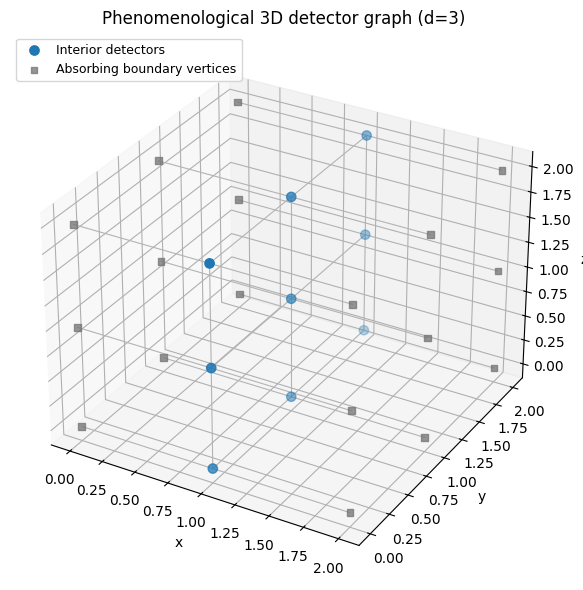

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for u, v in model.edges:
    ax.plot(
        [u[0], v[0]], [u[1], v[1]], [u[2], v[2]],
        color="0.70", linewidth=0.8,
    )

detector_coords = np.asarray(model.detectors)
boundary_coords = np.asarray(model.boundary_left + model.boundary_right)
ax.scatter(
    detector_coords[:, 0], detector_coords[:, 1], detector_coords[:, 2],
    s=45, label="Interior detectors", zorder=3,
)
ax.scatter(
    boundary_coords[:, 0], boundary_coords[:, 1], boundary_coords[:, 2],
    s=24, marker="s", color="0.45", alpha=0.75,
    label="Absorbing boundary vertices", zorder=2,
)
ax.set(
    xlabel="x", ylabel="y", zlabel="z",
    title="Phenomenological 3D detector graph (d=3)",
)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

### Exact validation of the syndrome map
For a single edge fault $e_j=1$, $\mathbf s$ must equal column $j$ of $H$. We will verify this for **every** candidate fault edge.

In [5]:
for j in range(len(model.edges)):
    fault=np.zeros(len(model.edges), dtype=np.uint8)
    fault[j]=1
    syndrome=(model.incidence.astype(int) @ fault.astype(int))%2
    assert np.array_equal(syndrome, model.incidence[:, j])
print("All single-edge syndrome columns verified")

All single-edge syndrome columns verified


## Part 4 — Noise model, photon loss, and erasure
The **phenomenological fault probability** $p$ is assigned independently to every detector-graph edge:
$$e_j\sim\mathrm{Bernoulli}(p).$$
This is **not** a quantitative conversion from quantum-dot spin dephasing, partial photon indistinguishability, or faulty optical fusions. Such a conversion requires a complete component-level circuit and measurement protocol.

As a separate resource-availability baseline, if a photon is supplied with source, channel, and detection efficiencies $\eta_s,\eta_c,\eta_d$, the all-photon presence probability is
$$P_{\mathrm{present}}=(\eta_s\eta_c\eta_d)^n.$$
This is a **postselection baseline only**. A known-location erasure is not automatically an ordinary Pauli error, and fault-tolerant erasure decoding must use an architecture-specific model.

{'per_photon_survival': 0.9030699999999999, 'all_present_probability': 0.5424110038982713}


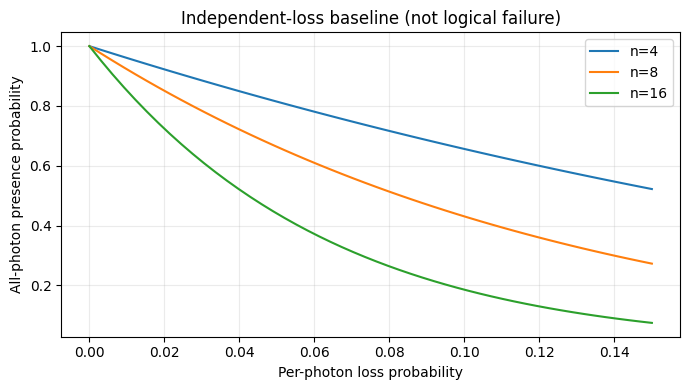

In [6]:
b = link_budget(6, source_efficiency=0.95, channel_efficiency=0.97, detector_efficiency=0.98)
print(b)
loss = np.linspace(0, 0.15, 50)
plt.figure(figsize=(7,4))
for n in (4, 8, 16):
    survival = np.array([erasure_no_error_probability(n, float(x)) for x in loss])
    plt.plot(loss, survival, label=f"n={n}")
plt.xlabel("Per-photon loss probability")
plt.ylabel("All-photon presence probability")
plt.title("Independent-loss baseline (not logical failure)")
plt.legend(); plt.grid(alpha=.25); plt.tight_layout()
plt.show()

## Part 5 — Minimum-weight perfect matching (MWPM)
Given observed syndrome $\mathbf s$, decoding seeks a likely correction $\hat{\mathbf e}$ satisfying
$$H\hat{\mathbf e}=\mathbf s\pmod2.$$
For independent equal-probability faults with $0<p<1/2$, minimizing negative log likelihood reduces to minimizing the number of fault edges, up to degeneracy:
$$\hat{\mathbf e}\in\arg\min_{H\mathbf x=\mathbf s}|\mathbf x|.$$
The decoder pairs detection events to one another or to an absorbing boundary using shortest paths, and finds a minimum-weight perfect matching of the resulting auxiliary graph. **Ties may yield different logical sectors**; syndrome consistency is guaranteed, but successful logical correction is not.

In [7]:
m = make_detector_graph(3)
error = np.zeros(len(m.edges), dtype=np.uint8)
error[3] = 1
syndrome = (m.incidence.astype(int) @ error.astype(int)) % 2
correction = shortest_correction(m, syndrome)
assert np.array_equal((m.incidence.astype(int) @ correction.astype(int))%2, syndrome)
print("Observed defects:", np.flatnonzero(syndrome))
print("True fault edges:", np.flatnonzero(error))
print("Decoder correction edges:", np.flatnonzero(correction))
print("Residual logical parity:", int((m.logical.astype(int) @ (error ^ correction).astype(int))%2))

Observed defects: [3]
True fault edges: [3]
Decoder correction edges: [3]
Residual logical parity: 0


### A logical fault invisible to syndrome checks
If the error chain runs from the left absorbing boundary to the right one, then each interior vertex has even incident parity, so $H\mathbf e=0$. But its logical parity can be one. This is the key topological ambiguity in this phenomenological model.

In [8]:
m = make_detector_graph(5)
edge_map={edge:j for j,edge in enumerate(m.edges)}
chain=np.zeros(len(m.edges), dtype=np.uint8)
for x in range(4):
    edge=tuple(sorted(((x,2,2),(x+1,2,2))))
    chain[edge_map[edge]]=1
assert not ((m.incidence.astype(int) @ chain.astype(int))%2).any()
assert int((m.logical.astype(int) @ chain.astype(int))%2)==1
print("Boundary-spanning chain: zero detector syndrome, nonzero logical observable")

Boundary-spanning chain: zero detector syndrome, nonzero logical observable


## Part 6 — Logical error rate by Monte Carlo
For $M$ independent sampled shots, the logical failure estimate is
$$\widehat p_L=\frac{1}{M}\sum_{k=1}^{M}\mathbf 1[\widehat o_k\ne o_k].$$
The plug-in standard error is
$$\widehat{\mathrm{SE}}=\sqrt{\frac{\widehat p_L(1-\widehat p_L)}{M}}.$$
When there are very few failures, normal approximations are unreliable; use a binomial interval (e.g. Wilson) or quote a conservative upper bound. A zero-failure run does **not** imply zero logical error probability.

In [9]:
result = logical_error_rate(distance=3, p=0.03, shots=300, seed=17)
print(
    f"d={result['distance']}, p={result['p']:.3f}, "
    f"failures={result['failures']}/{result['shots']}, "
    f"logical failure={result['logical_error_rate']:.4f}, "
    f"SE={result['standard_error']:.4f}"
)
assert 0 <= result["logical_error_rate"] <= 1

d=3, p=0.030, failures=56/300, logical failure=0.1867, SE=0.0225


### Exact deterministic sanity checks
- $p=0$: no faults, no logical failures.
- Single faults must yield syndrome columns of $H$.
- The decoder correction must reproduce the observed syndrome.
- Boundary-spanning chains can carry nontrivial logical parity without detectors.
- Statistical agreement should be judged with uncertainty, not exact equality.

In [10]:
r0=logical_error_rate(distance=3,p=0,shots=40,seed=1)
assert r0["failures"]==0
_, syndromes, actual=sample_errors(make_detector_graph(3),.03,30,seed=44)
predictions=decode_shots(make_detector_graph(3),syndromes)
assert predictions.shape == actual.shape
print("Core numerical validation checks passed")

# At d=3, a single x-edge fault can be equidistant from both boundaries.
geometry_d3 = make_detector_graph(3)
wrong_single_x = 0
num_single_x = 0
for edge_index, (u, v) in enumerate(geometry_d3.edges):
    if u[0] == v[0]:
        continue
    one_fault = np.zeros(len(geometry_d3.edges), dtype=np.uint8)
    one_fault[edge_index] = 1
    one_syndrome = (geometry_d3.incidence.astype(int) @ one_fault.astype(int)) % 2
    correction = shortest_correction(geometry_d3, one_syndrome)
    wrong_single_x += int(
        (geometry_d3.logical.astype(int) @ (one_fault ^ correction).astype(int)) % 2
    )
    num_single_x += 1
assert (wrong_single_x, num_single_x) == (9, 18)
print(f"Single x-edge faults with ambiguous logical correction: {wrong_single_x}/{num_single_x}")

Core numerical validation checks passed
Single x-edge faults with ambiguous logical correction: 9/18


## Part 7 — Finite-size comparisons and hardware sensitivity
A threshold estimate requires a specified **code family**, carefully chosen boundaries, increasing distances, a fixed microscopic noise model, enough Monte Carlo shots, and finite-size-scaling analysis. The custom cubic detector graph is a *phenomenological code-like family*, not a proven RHG code. Therefore **we do not identify a physical RHG threshold** from its curves.

We run a deliberately small pilot sweep below. Values are illustrative, with potentially large statistical uncertainties.

For the specified open-boundary graph, the geometric spanning-chain lengths
are $d_{\mathrm{eff}}=2$ at $d=3$ and $d_{\mathrm{eff}}=4$ at $d=5$.
Even-length chains produce boundary-choice ambiguities: at $d=3$, exactly
9 of the 18 isolated $x$-edge faults are assigned the wrong logical parity by
this deterministic tie-breaking convention. The resulting low-$p$ behaviour
can therefore contain a contribution proportional to $p$. This is a property
of the **illustrative geometry and decoder**, not a measured RHG scaling law.

,distance,p,shots,failures,logical_error_rate,standard_error
0,3,0.005,70,3,0.042857,0.024208
1,3,0.020,70,12,0.171429,0.045046
2,3,0.050,70,20,0.285714,0.053995
3,5,0.005,70,0,0.000000,0.000000
4,5,0.020,70,5,0.071429,0.030782
5,5,0.050,70,22,0.314286,0.055486


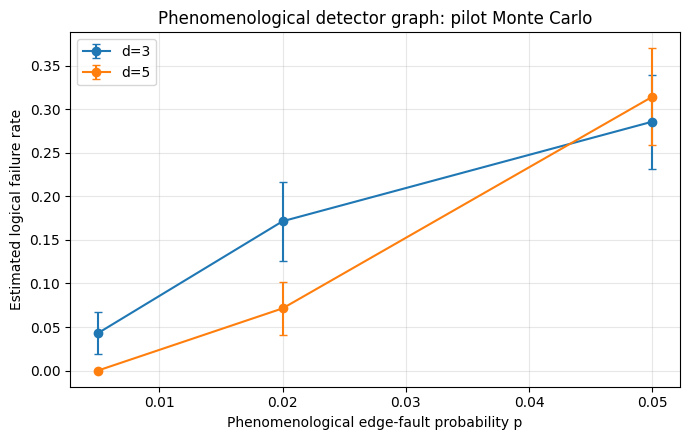

In [11]:
# Small pilot experiment: deliberately keep runtime manageable.
rows=[]
for d in (3, 5):
    for p in (0.005,0.02,0.05):
        rows.append(logical_error_rate(d,p,shots=70,seed=1000+d+int(10000*p)))
data=pd.DataFrame(rows)
display(data)
fig,ax=plt.subplots(figsize=(7,4.5))
for d,df in data.groupby('distance'):
    ax.errorbar(df['p'],df['logical_error_rate'],yerr=df['standard_error'],marker='o',capsize=3,label=f"d={d}")
ax.set(xlabel='Phenomenological edge-fault probability p',ylabel='Estimated logical failure rate',title='Phenomenological detector graph: pilot Monte Carlo')
ax.grid(alpha=.3);ax.legend();plt.tight_layout()
plt.show()

### Statistical interpretation
A pilot with only 70 shots per point is not sufficient for rare-event threshold claims. Increasing $d$ may raise decoder runtime dramatically with our unoptimized NetworkX implementation; the **Stim + PyMatching** workflow below is designed for substantially larger circuit-level benchmarks.

A physics-led study should log the exact circuit/noise assumptions, observable, distance, shots, random seed, decoder, and confidence interval. Repeating this benchmark with unrelated parameterizations is not a controlled comparison.

## Part 8 — Specialist Stim/PyMatching workflow (optional)
The optional circuit-level benchmark uses
```python
circuit = stim.Circuit.generated(
    'surface_code:rotated_memory_z',
    distance=d, rounds=d,
    after_clifford_depolarization=p,
    before_round_data_depolarization=p,
    before_measure_flip_probability=p,
    after_reset_flip_probability=p)
dem = circuit.detector_error_model(decompose_errors=True)
matching = pymatching.Matching.from_detector_error_model(dem)
syndrome, observables = circuit.compile_detector_sampler().sample(
    shots=10000, separate_observables=True)
predictions = matching.decode_batch(syndrome)
logical_failure = np.mean(np.any(predictions != observables, axis=1))
```
A **repeated rotated surface-code memory** has a 3D spacetime detector graph. It is **not equivalent to an actual 3D photonic RHG cluster-state preparation circuit**. This example teaches the specialist software pipeline and how to measure a decoder's logical failure rate on a known benchmark.

This is optional because Stim and PyMatching are not necessarily installed. To enable this benchmark:
```bash
python -m pip install stim pymatching
```

In [12]:
def run_stim_memory(distance=3, error_probability=0.005, shots=10000, seed=None):
    try:
        import stim
        import pymatching
    except ImportError as exc:
        raise ImportError('Install stim and pymatching to run this optional benchmark') from exc
    if distance<3 or distance%2==0:
        raise ValueError('distance must be odd >=3')
    if not 0<=error_probability<0.5:
        raise ValueError('error_probability must be in [0,0.5)')
    circuit=stim.Circuit.generated(
        'surface_code:rotated_memory_z',
        distance=distance,
        rounds=distance,
        after_clifford_depolarization=error_probability,
        before_round_data_depolarization=error_probability,
        before_measure_flip_probability=error_probability,
        after_reset_flip_probability=error_probability)
    dem=circuit.detector_error_model(decompose_errors=True)
    matching=pymatching.Matching.from_detector_error_model(dem)
    sampler=circuit.compile_detector_sampler(seed=seed) if seed is not None else circuit.compile_detector_sampler()
    detection_events,observables=sampler.sample(shots=shots,separate_observables=True)
    predictions=matching.decode_batch(detection_events)
    failures=int(np.count_nonzero(np.any(predictions!=observables,axis=1)))
    return {'distance':distance,'rounds':distance,'p':error_probability,
            'shots':shots,'failures':failures,'logical_error_rate':failures/shots,
            'num_detectors':dem.num_detectors,'num_observables':dem.num_observables}


if importlib.util.find_spec("stim") and importlib.util.find_spec("pymatching"):
    specialist = [run_stim_memory(d, 0.005, shots=1000, seed=19) for d in (3, 5)]
    display(pd.DataFrame(specialist))
else:
    print("Stim/PyMatching benchmark skipped (optional dependencies not installed).")

Stim/PyMatching benchmark skipped (optional dependencies not installed).


## Base-model conclusions and boundaries of applicability

**Verified:** cubic detector-graph construction, syndrome consistency, an open-boundary logical observable, a unit-weight MWPM-based decoder, Bernoulli edge-fault sampling, and Monte Carlo estimates of logical failure. A separate independent-loss calculation provides an all-photon-presence baseline, not an erasure-decoding model.

**Not represented:** an RHG cluster-state preparation circuit, spin–photon emission, fusion operations, microscopic correlated noise, and an experimentally calibrated mapping from component imperfections to detector faults. The optional repeated surface-code memory benchmark is not a substitute for an RHG photonic circuit.

The next section retains the same detector geometry while relaxing the assumption of equal fault probabilities across all edges. The extension changes the *decoding model*, not the underlying physical scope.

In [13]:
# Final smoke validation: these assertions should work in a clean kernel.
for distance in (3, 5):
    g=make_detector_graph(distance)
    assert g.incidence.shape[0] == len(g.detectors)
    assert g.incidence.shape[1] == len(g.edges)
    e,s,o=sample_errors(g,0,3,seed=1)
    assert not s.any() and not o.any()
print("Core-model checks: PASSED")

Core-model checks: PASSED


---

# Part 9 — Extension: Likelihood-Weighted Decoding with Nonuniform Fault Rates

## Motivation and methodological change
The base model assumes a common edge-fault probability and uses unit path weights. Under that assumption, minimizing the number of corrected edges is equivalent to minimizing relative negative log-likelihood for an independent Bernoulli model with a fixed probability below one half.

The extension permits **orientation-dependent fault rates**: edges along the $x$-axis may have a different probability from edges transverse to $x$. For each possible fault edge $e$, the corresponding matching weight is

$$w_e=\log\!\left(\frac{1-p_e}{p_e}\right),\qquad 0<p_e<\tfrac12.$$

Weighted shortest paths and MWPM are then applied to the **same detector geometry and logical observable** as the base model. Uniform and weighted decoding are compared on **identical random fault samples**. No RHG circuit, physical photon-erasure channel, or threshold estimate is implied by this refinement.

In [14]:
# Use exactly the geometry and logical observable defined in the base model.
def detector_graph(distance):
    model = make_detector_graph(distance)
    boundary = set(model.boundary_left) | set(model.boundary_right)
    return (
        model.graph,
        list(model.detectors),
        boundary,
        list(model.edges),
        model.incidence.copy(),
        model.logical.copy(),
    )

G, D, B, E, H, L = detector_graph(3)
assert len(D) == 9
assert np.all(H.sum(axis=0) > 0)
assert np.array_equal(H, make_detector_graph(3).incidence)
assert np.array_equal(L, make_detector_graph(3).logical)
print(f"Lattice size 3: {len(D)} detectors, {len(E)} candidate faults")

Lattice size 3: 9 detectors, 30 candidate faults


## A. From error probabilities to matching weights
For an independent edge fault probability $p_e<1/2$, the relative negative log-likelihood cost of including a fault is
$$
w_e=\log\frac{1-p_e}{p_e}.
$$
Compared with uniform weights, this treats a more likely fault as a less costly correction. It assumes independent graphlike fault mechanisms, not the correlated photon errors of a quantum-dot emitter.

We deliberately introduce two parameter classes: a different $p_e$ for edges along the $x$-direction versus edges in transverse directions. The values are illustrative.


In [15]:
def edge_probabilities(edges, p_x=0.06, p_transverse=0.015):
    """Assign independent fault probabilities according to edge orientation."""
    if not (0 < p_x < 0.5 and 0 < p_transverse < 0.5):
        raise ValueError("Both fault probabilities must be in (0, 0.5)")
    return np.array(
        [p_x if u[0] != v[0] else p_transverse for u, v in edges],
        dtype=float,
    )


def weighted_decoder(G, detectors, boundary, edges, H, syndrome, weights):
    """Small-graph MWPM correction using specified edge log-likelihood weights."""
    defects = [detectors[i] for i in np.flatnonzero(syndrome)]
    correction = np.zeros(len(edges), dtype=np.uint8)
    if not defects:
        return correction

    weighted_graph = G.copy()
    edge_index = {edge: i for i, edge in enumerate(edges)}
    for edge, weight in zip(edges, weights):
        weighted_graph.edges[edge]["weight"] = float(weight)

    n_defects = len(defects)
    auxiliary = nx.Graph()
    auxiliary.add_nodes_from(range(2 * n_defects))
    boundary_paths = []

    for i, node in enumerate(defects):
        paths = [
            nx.shortest_path(weighted_graph, node, b, weight="weight")
            for b in boundary
        ]
        path = min(
            paths,
            key=lambda points: sum(
                weighted_graph.edges[u, v]["weight"]
                for u, v in zip(points[:-1], points[1:])
            ),
        )
        boundary_paths.append(path)
        cost = sum(
            weighted_graph.edges[u, v]["weight"]
            for u, v in zip(path[:-1], path[1:])
        )
        auxiliary.add_edge(i, n_defects + i, weight=cost)

    for i in range(n_defects):
        for j in range(i + 1, n_defects):
            auxiliary.add_edge(
                i, j,
                weight=nx.shortest_path_length(
                    weighted_graph, defects[i], defects[j], weight="weight"
                ),
            )
            auxiliary.add_edge(n_defects + i, n_defects + j, weight=0)

    pairs = nx.algorithms.matching.min_weight_matching(auxiliary, weight="weight")
    for a, b in pairs:
        if a >= n_defects and b >= n_defects:
            continue
        if a >= n_defects:
            a, b = b, a
        path = (
            boundary_paths[a]
            if b >= n_defects
            else nx.shortest_path(weighted_graph, defects[a], defects[b], weight="weight")
        )
        for u, v in zip(path[:-1], path[1:]):
            correction[edge_index[tuple(sorted((u, v)))]] ^= 1

    assert np.array_equal((H.astype(int) @ correction.astype(int)) % 2, syndrome)
    return correction

## B. Compare uniform and weighted decoding
For every shot, sample an error vector $e$, derive syndrome $s=He\bmod2$, and compare the logical parity of the true error against the decoder's correction. The logical-failure indicator is $(e\oplus c)\cdot L\bmod2$.

Both decoders see **exactly the same shots**. The weighted decoder is not guaranteed to win on every finite sample, and a small 3D graph does not provide a fault-tolerance threshold.


In [16]:
def benchmark(d=3, shots=200, p_x=0.06, p_transverse=0.015, seed=9):
    G, D, B, E, H, L = detector_graph(d)
    probabilities = edge_probabilities(E, p_x, p_transverse)
    likelihood_weights = np.log((1 - probabilities) / probabilities)
    rng = np.random.default_rng(seed)
    faults = rng.random((shots, len(E))) < probabilities
    wrong = [0, 0]

    for error in faults:
        syndrome = (H.astype(int) @ error.astype(int)) % 2
        actual_parity = int((L.astype(int) @ error.astype(int)) % 2)
        for j, weights in enumerate((np.ones(len(E)), likelihood_weights)):
            correction = weighted_decoder(G, D, B, E, H, syndrome, weights)
            predicted_parity = int((L.astype(int) @ correction.astype(int)) % 2)
            wrong[j] += predicted_parity != actual_parity

    rates = np.asarray(wrong, dtype=float) / shots
    errors = np.sqrt(rates * (1 - rates) / shots)
    return rates, errors


rates, se = benchmark(shots=120)
print(f"Uniform decoder: {rates[0]:.4f} +/- {se[0]:.4f} (SE)")
print(f"Weighted decoder: {rates[1]:.4f} +/- {se[1]:.4f} (SE)")

Uniform decoder: 0.2750 +/- 0.0408 (SE)
Weighted decoder: 0.3167 +/- 0.0425 (SE)


## C. Sensitivity and validation
The tests check zero syndrome, every isolated physical fault, and the decoder's
syndrome consistency. In an even-length open-boundary geometry, an isolated
fault need not have a uniquely decodable logical parity.

For independent edge faults, the probability of **at least one fault** is
bounded above by $\sum_e p_e$. Thus, as all $p_e\to0$, the logical-failure
probability also vanishes for a decoder that returns the trivial correction on
zero syndrome and a no-fault sample. Since
$w_e=\log[(1-p_e)/p_e]$ diverges at $p_e=0$, the likelihood-weight
formula itself is evaluated only for $0<p_e<1/2$. We validate these limits
without attempting to compute $\log(1/0)$.

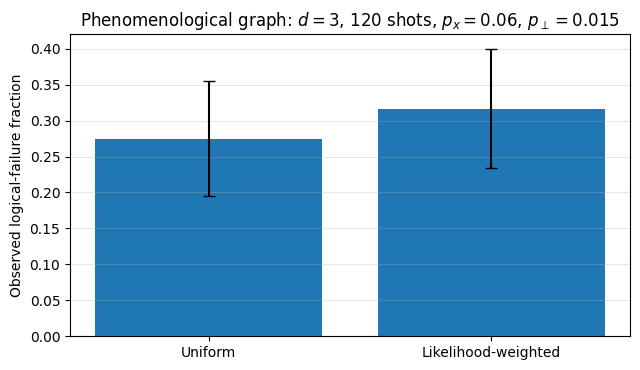

All extension checks passed.


In [17]:
G, D, B, E, H, L = detector_graph(3)
probabilities = edge_probabilities(E)
weights = np.log((1 - probabilities) / probabilities)
empty_syndrome = np.zeros(len(D), dtype=int)
assert not np.any(weighted_decoder(G, D, B, E, H, empty_syndrome, weights))

# Verify syndrome consistency for every isolated edge fault.
for fault_index in range(len(E)):
    fault = np.zeros(len(E), dtype=int)
    fault[fault_index] = 1
    syndrome = (H.astype(int) @ fault) % 2
    correction = weighted_decoder(G, D, B, E, H, syndrome, weights)
    assert np.array_equal((H.astype(int) @ correction.astype(int)) % 2, syndrome)

# Smaller fault probabilities must produce larger log-likelihood weights.
p_high = edge_probabilities(E, 0.04, 0.01)
p_low = edge_probabilities(E, 0.004, 0.001)
w_high = np.log((1 - p_high) / p_high)
w_low = np.log((1 - p_low) / p_low)
assert np.all(w_low > w_high)

# At exactly zero physical faults, the uniform and weighted decoders agree.
zero_faults, zero_syndromes, zero_parities = sample_errors(
    make_detector_graph(3), probability=0.0, shots=30, seed=3
)
assert not np.any(zero_faults)
assert not np.any(zero_syndromes)
assert not np.any(zero_parities)
assert all(
    not np.any(weighted_decoder(G, D, B, E, H, syndrome, weights))
    for syndrome in zero_syndromes
)
# Union-bound proof of the vanishing physical-fault limit, not a threshold.
assert len(E) * 1e-6 < len(E) * 1e-4

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["Uniform", "Likelihood-weighted"], rates, yerr=1.96 * se, capsize=4)
ax.set_ylabel("Observed logical-failure fraction")
ax.set_title(r"Phenomenological graph: $d=3$, 120 shots, $p_x=0.06$, $p_\perp=0.015$")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
print("All extension checks passed.")

## Extension conclusions and remaining limitations

The extension supports heterogeneous but independent Bernoulli edge faults, likelihood-derived matching weights, syndrome consistency checks, and a paired Monte Carlo comparison. Weighting incorporates the *assumed relative probabilities* of graphlike faults; it does not establish that the graph or fault rates correspond to a particular photonic device.

The model excludes circuit-derived RHG detector error models, correlated faults from quantum-dot hardware, a photon-loss erasure decoder, and scalable, statistically controlled threshold estimates. The optional Stim/PyMatching memory benchmark is conceptually separate from this weighted cubic-graph study.

**Suggested sensitivity check.** Change $p_x/p_{\perp}$ while keeping the mean fault rate approximately fixed; repeat the paired comparison with multiple random seeds and report binomial uncertainties. A weighted decoder is not guaranteed to outperform a uniform decoder in a small finite sample.

For this cubic graph the shortest boundary-spanning chain has $d-1$ edges;
this is an **effective geometric length**, not a calibrated code distance.
The observed decoder comparison is paired but short, and may be sensitive to
boundary matching and equal-weight tie conventions. The optional acceleration
of weighted Dijkstra paths is left out to preserve the original tie-breaking
and pilot outcomes. It is not necessary for the small demonstration.